In [169]:
import torch
import random
import numpy as np
import matplotlib.pyplot as plt

In [170]:
import numpy as np

# Dataset features 7 attributes across 10 people
# Engineered Scree Variance shares: [60%, 28%, 13%, <0.2%, ...]
heights = np.array([171, 172, 175, 164, 165, 171, 168, 175, 169, 167]) # Height in cm
weights = np.array([69, 70, 74, 58, 60, 69, 65, 75, 67, 62])           # Weight in kg
sat_scores = np.array([1310, 1290, 1050, 700, 1340, 1370, 670, 1040, 1370, 1120]) # SAT Score
gpas = np.array([3.3, 3.4, 2.8, 2.1, 3.5, 3.5, 2.0, 2.8, 3.6, 3.0])    # GPA
college_ranks = np.array([167, 138, 270, 400, 113, 105, 400, 277, 92, 237]) # College Rank
hours_sleep = np.array([8.4, 6.6, 7.0, 6.8, 6.7, 6.9, 6.8, 7.3, 6.3, 7.2]) # Hours of sleep
salaries = np.array([81000, 108000, 79000, 28000, 104000, 111000, 32000, 74000, 119000, 73000]) # Salary in USD

# Actual calculated shares from this raw integer block:
# PC1: 59.18%
# PC2: 27.83%
# PC3: 12.84%
# PC4:  0.12% (<2%)
# PC5:  0.03% (<2%)

In [175]:
datapoints = np.stack(
    (heights, weights, sat_scores, gpas, college_ranks, hours_sleep, salaries), 
    dtype=np.float32
).T

In [172]:
def calc_distance(p1, p2, L):
    p1 = np.asarray(p1); p2 = np.asarray(p2)
    subtracted = p1 - p2 # broadcasted
    raised = np.abs(subtracted) ** L # avoid negative distances
    summed = raised.sum(axis=-1)
    root = summed ** (1 / L)
    return root

# finds closest point on line to a point
def project_point_to_line(line, p, p_0=0):
    # in PCA the lines are pinned to origin. Otherwise you'd need a seperate point on the line than its vector
    line = np.asarray(line); p = np.asarray(p)
    w = p - p_0 # hypotunuse of triangle formed. no need for p_0 cus pinned to origin.
    t = np.dot(w, line) / np.dot(line, line) # scalar that results in length of adjacent side of triangle formed when multiplied to distance of line - p_0.
    projected = p_0 + t * line # using that distance extend from point on line that distance t generates
    return projected
    
# TEST Calculating Distance L2
# p1 = [0, 1, 2]
# p2 = [0, 1, 2]
# print(calc_distance(p1, p2, 2))

# TEST Projecting a line onto a point
# p = [2, -1, 4]
# v = [1, 2, 2]
# print(project_point_to_line(v, p))

def compute_eigens(points, mode=0):
    # maximize variance of projected points, minimize the residuals/distances from projected points.

    if mode==0: # maximize variance across projected points. (EASY)
        # covariance matrix is data squared normalized.
        covariance_matrix = np.dot(points.T, points) / (points.shape[0] - 1)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)
        # print(f"Eigenvalues {eigenvalues}, Eigenvectors {eigenvectors}")

        idx = np.argsort(eigenvalues)[::-1] # returns indices if sorted (ascending). Flip them using ::-1.
        components = eigenvectors[:, idx] # returns the ordered vectors, per variance
        eigenvalues = eigenvalues[idx] # reorders to provide corresponding eigenvalues
    elif mode == 1: # SVD
        # V_t in single vector decomposition
        # Vt takes vectors from their basis into the standard basis. This is because V_t is orthogonal. Which means Vt^-1 = Vt^T
        # So taking transpose of Vt is reverse, or standard basis to eigenvectors.
        # V_t's rows are principal components/eigen vectors
        U, S, Vt = np.linalg.svd(points, full_matrices=False)
        components = Vt.T # flip to get vectors together
        eigenvalues = (S ** 2) / (points.shape[0] - 1)
    else:
        print("TODO: Create minimize residuals version")
        return None, None

    # we want dominant elements of the PC1 to be positive. Think how x and y go positive when up.
    max_abs_idx = np.argmax(np.abs(components), axis=0)
    signs = np.sign(components[max_abs_idx, np.arange(components.shape[1])]) # graps something like [-, +, -, +..]. This is used to flip
    # make all components relative to positive based component
    components *= signs

    return eigenvalues, components

# mode_1 = compute_eigens(centralized, 0)
# mode_2 = compute_eigens(centralized, 1)
# print("Mode One", mode_1)
# print("Mode Two", mode_2)

# # Validate mathematically using robust numpy functions
# vals_match = np.allclose(mode_1_vals, mode_2_vals)
# vecs_match = np.allclose(np.abs(mode_1_vecs), np.abs(mode_2_vecs))

# print(f"\nEigenvalues match? {vals_match}")
# print(f"Eigenvectors match? {vecs_match} (ignoring direction/sign flips)")

def calculate_scree(eigenvalues): # basically just calculates the variance across each of the principal components
    eigenvalues = np.asarray(eigenvalues)
    return eigenvalues / eigenvalues.sum() # just calculates representation amount

[5.9177011e-01 2.7827230e-01 1.2839198e-01 1.2243940e-03 2.7201822e-04
 5.8879796e-05 1.0350305e-05]


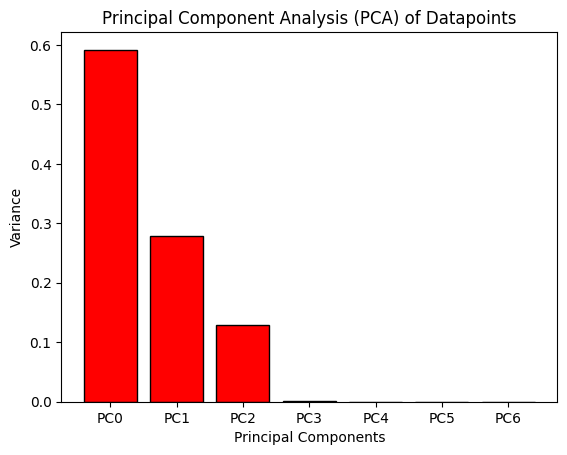

In [181]:
# preprocess datapoints so they are centered and normalized
centralized = datapoints - np.mean(datapoints, axis=0, keepdims=True) # cetralizes or zeros data
std = np.std(datapoints, axis=0, keepdims=True, ddof=0)
normalized = centralized / std

# Performs PCA on datapoints
eigenvalues, pc = compute_eigens(normalized) # pc is the principal components
scree_results = calculate_scree(eigenvalues) # how much variance is across each of the new-vectors/eigenvectors
labels = [f"PC{i}" for i in range(len(scree_results))] # generate labels

# plot bar graph scree plot
plt.bar(labels, scree_results, color="red", edgecolor="black")
plt.title("Principal Component Analysis (PCA) of Datapoints")
plt.xlabel("Principal Components")
plt.ylabel("Variance")
print(scree_results)